<a href="https://colab.research.google.com/github/liamholland2000/skills-introduction-to-github/blob/main/Assignment2_24258164_sem1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Transfer Learning with Med MNIST.

In this assignment you will use transfer learning to train a model of your choice on a sub-dataset from the [MedMNIST datasets](https://medmnist.com/). ![](https://github.com/tonyscan6003/etivities/blob/main/medmnist.JPG?raw=true)

* The [MedMNIST package](https://github.com/MedMNIST/MedMNIST/blob/main/examples/getting_started.ipynb) allows the data to be imported directly as a pytorch dataset.

* You may select any of the datasets using Multi-class/binary classification. The goal is to acheve accuracy levels comparable to the benchmark results shown on the medmnist site. Dataloading for pytorch is setup in the notebook, you wil need to modify the code slightly depending on your dataset of choice.

* Some datasets use black and white images, so you will need to [at least concatenate](https://towardsdatascience.com/transfer-learning-on-greyscale-images-how-to-fine-tune-pretrained-models-on-black-and-white-9a5150755c7a) the input image channels (to 3 channels) for compatibility with the models pre-trained on imageNet.

* Some of the MedMNIST datasets don't contain too much data so Data augmentation may be essentila essential to avoid overfitting. In pytorch data augmentation is performed using the [transforms.v2](https://pytorch.org/vision/main/transforms.html) modules.

* In this notebook: You will need to import a model, and perform training. Tranfer Learning for computer vision is detailed [here](https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)

* [Tensorboard can be imported](https://pytorch.org/tutorials/beginner/introyt/tensorboardyt_tutorial.html) to display results.

* Please only include one example of transfer learning in the submitted notebook. Making sure training curves/results are clearly visible. If you have trained additional transfer learning models (i.e. that were less successful) please add this as a table or report at the end of the notebook and/or in your final forum post.




# 1. Install & Import Packages

In [2]:
!pip install medmnist
!pip install torchinfo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 7.0 MB/s eta 0:00:00


In [3]:
import torch
from torch import nn
from torchvision import datasets, models
from torchvision.transforms import ToTensor, v2, Pad, Grayscale
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
import numpy as np

## 2. Setup & Import Dataset
The [MedMNSIT](https://medmnist.com/) package (imported above) makes available several medical datasets available to access.

You can change the `data_flag` variable (dataset names are all lower case letters) to the dataset of your choice (Take care to note the parameters e.g. number of input channels below that will affect your model)



In [4]:
import medmnist
from medmnist import INFO, Evaluator

data_flag = 'bloodmnist'
download = True

BATCH_SIZE = 64

info = INFO[data_flag]
task = info['task']
n_channels = info['n_channels']
n_classes = len(info['label'])

print('Type of Machine Learning Task = ',task)
print('Number of Input Data Channels = ',n_channels)
print('Number of Classes = ',n_classes)
print('The batch size for this dataset will be = ',BATCH_SIZE)

DataClass = getattr(medmnist, info['python_class'])

Type of Machine Learning Task =  multi-class
Number of Input Data Channels =  3
Number of Classes =  8
The batch size for this dataset will be =  64


Transforms:
You can update the functions below with appropriate transforms for your particular use case.

* As well as being suitable for data augmention for image classification, the transforms.v2 package of torchvision extends transforms for object detection and segmentation tasks. An illustration of the transforms is shown [here](https://pytorch.org/vision/main/auto_examples/transforms/plot_transforms_illustrations.html#sphx-glr-auto-examples-transforms-plot-transforms-illustrations-py).
* Normalisation based on ImageNet parameters is included already. This should be used with all models pre-trained on ImageNet  





In [5]:
# Transforms for training and test/val

train_transforms = v2.Compose([
    v2.ToImage(),                                      # ensure PIL/ndarray -> image
    v2.ToDtype(torch.float32, scale=True),            # scale to [0,1] float32
    v2.RandomHorizontalFlip(p=0.5),                   # simple augmentation
    v2.RandomRotation(degrees=15),                    # small rotations
    v2.Normalize([0.485, 0.456, 0.406],
                 [0.229, 0.224, 0.225]),              # ImageNet stats
])

test_transforms = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize([0.485, 0.456, 0.406],
                 [0.229, 0.224, 0.225]),
])


Setup your Medmnist dataset.
* The convolution part of pre-trained networks (such as resnet) are compatable with any size input image. However they were trained on 224 x 224 size images, with early layers finding small scale features and deeper layers finding large scale features.
* For this transfer learning application to medical data, the gap between the original ImageNet domain and the medical images is wide. Therefore the size/scale of the input images is less important, however in general we would expect better performance with the larger input images (as they contain more features at different scales).
* You can add the `size=224` parameter to the dataset object calls, to load full size images. Only do this once you are confident in your training methodology (or if the dataset is small), as training with full size images will take longer.


In [6]:
train_dataset = DataClass(split='train', transform=train_transforms, download=download, size=224, mmap_mode='r')
val_dataset   = DataClass(split='val',   transform=test_transforms,  download=download, size=224, mmap_mode='r')
test_dataset  = DataClass(split='test',  transform=test_transforms,  download=download, size=224, mmap_mode='r')


100%|██████████| 1.54G/1.54G [11:01<00:00, 2.33MB/s]


The `Dataset` is passed as an argument to `DataLoader`. This wraps an
iterable over the dataset, and supports automatic batching, sampling,
shuffling and multiprocess data loading.

In [7]:
# Create data loaders.
train_dataloader = DataLoader(dataset=train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_dataloader = DataLoader(dataset=val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_dataloader = DataLoader(dataset=test_dataset, batch_size=BATCH_SIZE, shuffle=False)

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

Shape of X [N, C, H, W]: torch.Size([64, 3, 224, 224])
Shape of y: torch.Size([64, 1]) torch.int64


Plot some example augmented images

> Add blockquote



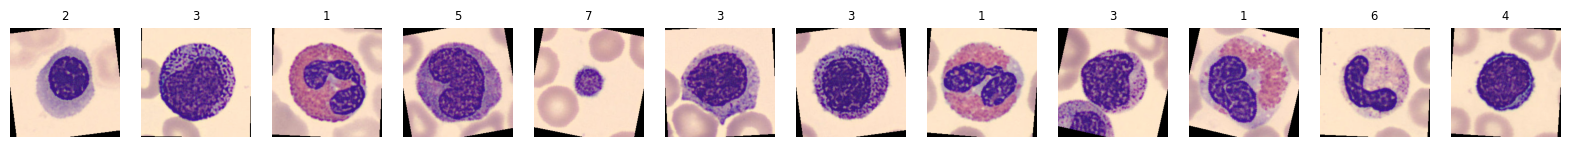

In [8]:
# Plot example augmented images
dataiter = iter(train_dataloader)
image_batch, labels_batch = next(dataiter)

n_plots = 12
fig, axarr = plt.subplots(1, n_plots, figsize=(20, 10))

# ImageNet mean & std (for un-normalising)
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

for i in range(n_plots):
    image = image_batch[i]

    # Convert from [C,H,W] tensor → numpy [H,W,C]
    disp_image = image.permute(1, 2, 0).cpu().numpy()

    # Un-normalise
    disp_image = std * disp_image + mean
    disp_image = np.clip(disp_image, 0, 1)

    axarr[i].imshow(disp_image)
    axarr[i].axis("off")

    # labels_batch[i] is shape [1], so take item()
    axarr[i].set_title(int(labels_batch[i].item()), fontsize='small')

plt.show()


# 3. Define Transfer Learning model
Pytorch has an inbuilt [models package](https://pytorch.org/vision/stable/models.html) that allows loading of popular models with pre-trained weights.

* We want to add an additional classifier stage (to the output of the network). How to setup the [model is detailed here](https://discuss.pytorch.org/t/load-only-a-part-of-the-network-with-pretrained-weights/88397/2).
* This additional classifier may just be a single layer or a cascade of fully connected layers with dropout.
* Note that the number of parameters in the convolutional part of the model will be same no what the input size is set to. However the output feature map size will vary with input image size (small for small image, large for large image). This means the number of parameters in the additional classifier will change depending on input image size.


In [9]:
# Get cpu, gpu or mps device for training.
device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using {device} device")

Using cuda device


# 4. Optimisation & Training Loop

Define a training loop that prints the loss from the training and validation set at least every epoch.
* You may choose to make the validation loss calculations more frequent so you can ensure training is progressing satisfactorily (especially with larger datasets).

* You can use tensorboard to visualise the [loss curves](https://pytorch.org/docs/stable/tensorboard.html))

* For multi-class classification classification problem we will use the  [CrossEntropy loss](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html). In this pytorch function, the input is the un-normalised logit value.

* You may  have to use [torch.squeeze](https://pytorch.org/docs/stable/generated/torch.squeeze.html) to reduce the dimensionality of the label tensor before passing it to the loss function (this due to how the dataset is configured and the loss will only accept 0D or 1D inputs)

In [10]:
from torchvision import models
from torch import nn

# --- Load a pretrained ResNet-18 backbone ---
try:
    weights = models.ResNet18_Weights.DEFAULT
    base_model = models.resnet18(weights=weights)
except AttributeError:
    base_model = models.resnet18(pretrained=True)

# --- Freeze convolutional backbone ---
for param in base_model.parameters():
    param.requires_grad = False

# --- Replace the classifier head ---
in_features = base_model.fc.in_features

base_model.fc = nn.Sequential(
    nn.Linear(in_features, 256),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(256, n_classes)
)

model = base_model.to(device)

print(model.fc)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 131MB/s]


Sequential(
  (0): Linear(in_features=512, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=256, out_features=8, bias=True)
)


In [11]:
from torch.utils.tensorboard import SummaryWriter
writer = SummaryWriter('runs')


In [12]:
from torch import nn, optim
import time
import copy

# --- Hyperparameters ---
NUM_EPOCHS = 15
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

# --- Loss function ---
criterion = nn.CrossEntropyLoss()

# --- Optimiser: only train the classifier head (fc) ---
optimizer = optim.Adam(model.fc.parameters(),
                       lr=LEARNING_RATE,
                       weight_decay=WEIGHT_DECAY)

# Optional: learning rate scheduler (decays LR when val loss plateaus)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=2,

)

def train_one_epoch(model, dataloader, optimizer, device):
    model.train()
    running_loss = 0.0
    running_corrects = 0
    total_samples = 0

    for inputs, labels in dataloader:
        inputs = inputs.to(device)
        # labels often come as [batch_size, 1] from MedMNIST
        labels = labels.squeeze().long().to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        # predictions
        _, preds = torch.max(outputs, 1)

        loss.backward()
        optimizer.step()

        batch_size = inputs.size(0)
        running_loss += loss.item() * batch_size
        running_corrects += torch.sum(preds == labels).item()
        total_samples += batch_size

    epoch_loss = running_loss / total_samples
    epoch_acc = running_corrects / total_samples

    return epoch_loss, epoch_acc


def evaluate(model, dataloader, device):
    model.eval()
    running_loss = 0.0
    running_corrects = 0
    total_samples = 0

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.squeeze().long().to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            _, preds = torch.max(outputs, 1)

            batch_size = inputs.size(0)
            running_loss += loss.item() * batch_size
            running_corrects += torch.sum(preds == labels).item()
            total_samples += batch_size

    epoch_loss = running_loss / total_samples
    epoch_acc = running_corrects / total_samples

    return epoch_loss, epoch_acc


# --- Main training loop with TensorBoard logging ---
best_model_wts = copy.deepcopy(model.state_dict())
best_val_acc = 0.0

since = time.time()

for epoch in range(NUM_EPOCHS):
    print(f"Epoch {epoch+1}/{NUM_EPOCHS}")
    print("-" * 30)

    train_loss, train_acc = train_one_epoch(model, train_dataloader, optimizer, device)
    val_loss, val_acc = evaluate(model, val_dataloader, device)

    # Step the scheduler based on validation loss
    scheduler.step(val_loss)

    # Log to TensorBoard
    writer.add_scalar('Loss/train', train_loss, epoch)
    writer.add_scalar('Loss/val', val_loss, epoch)
    writer.add_scalar('Accuracy/train', train_acc, epoch)
    writer.add_scalar('Accuracy/val', val_acc, epoch)

    print(f"Train Loss: {train_loss:.4f}  |  Train Acc: {train_acc:.4f}")
    print(f"Val   Loss: {val_loss:.4f}  |  Val   Acc: {val_acc:.4f}")

    # Deep copy best model (based on validation accuracy)
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_wts = copy.deepcopy(model.state_dict())
        print("** New best model found! **")

    print()

time_elapsed = time.time() - since
print(f"Training complete in {time_elapsed/60:.1f} minutes")
print(f"Best validation accuracy: {best_val_acc:.4f}")

# Load best model weights
model.load_state_dict(best_model_wts)

# (Optional) Save best model to disk
torch.save(model.state_dict(), "best_bloodmnist_resnet18.pt")
print("Best model saved to best_bloodmnist_resnet18.pt")


Epoch 1/15
------------------------------
Train Loss: 0.6554  |  Train Acc: 0.7853
Val   Loss: 0.3343  |  Val   Acc: 0.8989
** New best model found! **

Epoch 2/15
------------------------------
Train Loss: 0.3267  |  Train Acc: 0.8918
Val   Loss: 0.2942  |  Val   Acc: 0.8954

Epoch 3/15
------------------------------
Train Loss: 0.2769  |  Train Acc: 0.9051
Val   Loss: 0.2975  |  Val   Acc: 0.8919

Epoch 4/15
------------------------------
Train Loss: 0.2628  |  Train Acc: 0.9113
Val   Loss: 0.2414  |  Val   Acc: 0.9182
** New best model found! **

Epoch 5/15
------------------------------
Train Loss: 0.2471  |  Train Acc: 0.9175
Val   Loss: 0.2244  |  Val   Acc: 0.9223
** New best model found! **

Epoch 6/15
------------------------------
Train Loss: 0.2258  |  Train Acc: 0.9218
Val   Loss: 0.2713  |  Val   Acc: 0.8978

Epoch 7/15
------------------------------
Train Loss: 0.2250  |  Train Acc: 0.9251
Val   Loss: 0.2071  |  Val   Acc: 0.9287
** New best model found! **

Epoch 8/15
--

Initialise Tensorboard (use of tensorboard in colab notebooks is [detailed here](https://colab.research.google.com/github/tensorflow/tensorboard/blob/master/docs/tensorboard_in_notebooks.ipynb)). A [Pytorch tutorial](https://pytorch.org/tutorials/beginner/introyt/tensorboardyt_tutorial.html) shows how to setup the training and validation loop with pytorch.


In [13]:
#from torch.utils.tensorboard import SummaryWriter
#writer = SummaryWriter('runs')

# 5. Evaluate Model
You will need to setup an evaluation loop for the model to assess it's performance on the test dataset.

You may also obtain a classification report after final evaluation of the test dataset with the model using the code below. A confusion matrix can also be obtained and we will plot a few example images.



Test Accuracy: 0.9521

Classification report:

                                                                     precision    recall  f1-score   support

                                                           basophil       0.95      0.94      0.95       244
                                                         eosinophil       0.99      0.98      0.99       624
                                                       erythroblast       0.97      0.95      0.96       311
immature granulocytes(myelocytes, metamyelocytes and promyelocytes)       0.86      0.96      0.91       579
                                                         lymphocyte       0.92      0.97      0.94       243
                                                           monocyte       0.96      0.82      0.89       284
                                                         neutrophil       0.97      0.95      0.96       666
                                                           platelet       1.00  

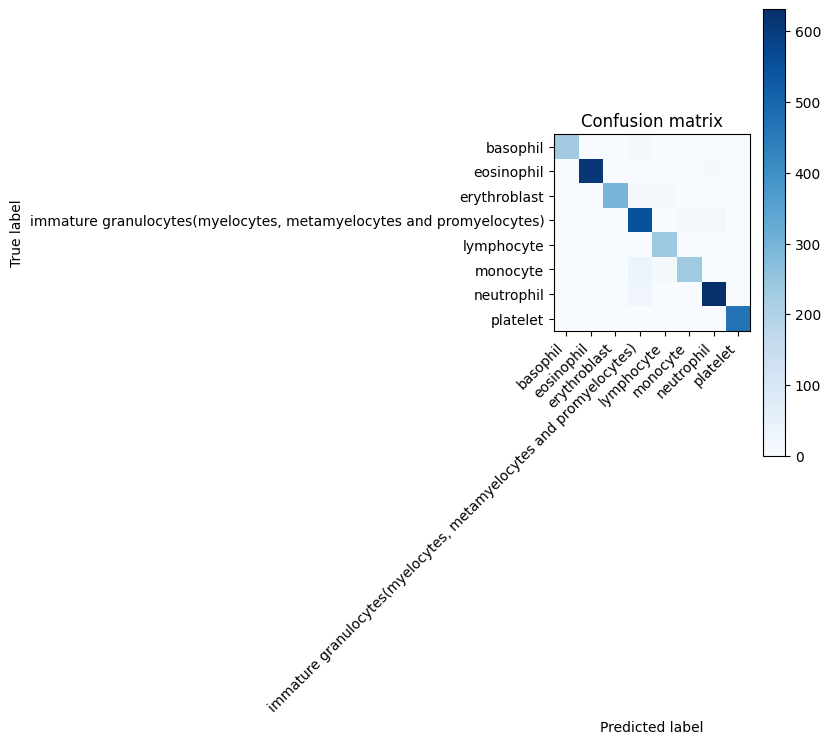

In [14]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

model.eval()

all_labels = []
all_preds = []

with torch.no_grad():
    for inputs, labels in test_dataloader:
        inputs = inputs.to(device)
        # MedMNIST labels often come as [batch_size, 1]
        labels = labels.squeeze().long().to(device)

        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

# Convert to numpy arrays
y_true = np.array(all_labels)
y_pred = np.array(all_preds)

# Overall test accuracy
test_acc = (y_true == y_pred).mean()
print(f"Test Accuracy: {test_acc:.4f}")

# Class names from MedMNIST info dict
# info['label'] is a dict with string keys "0", "1", ..., so we sort by int
classes = [info['label'][k] for k in sorted(info['label'].keys(), key=int)]

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

def plot_confusion_matrix(cm, title='Confusion matrix', cmap=plt.cm.Blues):
    plt.figure(figsize=(8, 8))
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45, ha="right")
    plt.yticks(tick_marks, classes)
    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

plot_confusion_matrix(cm)

print("\nClassification report:\n")
print(classification_report(y_true, y_pred, target_names=classes))

In [15]:
from sklearn.metrics import classification_report
print(classification_report(y_true, y_pred, target_names=classes))

                                                                     precision    recall  f1-score   support

                                                           basophil       0.95      0.94      0.95       244
                                                         eosinophil       0.99      0.98      0.99       624
                                                       erythroblast       0.97      0.95      0.96       311
immature granulocytes(myelocytes, metamyelocytes and promyelocytes)       0.86      0.96      0.91       579
                                                         lymphocyte       0.92      0.97      0.94       243
                                                           monocyte       0.96      0.82      0.89       284
                                                         neutrophil       0.97      0.95      0.96       666
                                                           platelet       1.00      0.99      0.99       470

                 

 # Comments about your Approach

The aim of this project was to apply transfer learning to one of the MedMNIST datasets and achieve performance in line with its published benchmarks. I chose BloodMNIST because it presents a genuinely multi-class medical classification problem (8 classes), with a reasonably large and well-balanced dataset, and because biological cell types often overlap visually — meaning the model actually has to work rather than just memorise patterns.

My approach was deliberately simple and aligned with how transfer learning is used in practice. I used ResNet-18 with ImageNet weights as the feature extractor and replaced the final classifier head with a small MLP (Linear → ReLU → Dropout → Linear) to match the eight blood-cell categories. I froze the entire backbone so that the optimiser focused only on training the new classifier. This kept training stable, avoided overfitting, and allowed the network to converge quickly.

One of the key considerations in this dataset is input size and domain shift. Although MedMNIST images are small, I loaded them at 224×224 so the model could exploit the spatial scale ResNet was originally trained on. I also applied light data augmentation (flips and rotations), mainly to avoid overfitting, given that some classes are visually similar and the dataset—though not tiny—can still benefit from variation.

The training setup was standard for multi-class classification: CrossEntropy loss, Adam optimiser on the new classifier head, and a ReduceLROnPlateau scheduler to dampen the learning rate when validation loss stopped improving. I logged the training and validation curves to TensorBoard to confirm that the model was actually learning and not just drifting or overfitting.

The model converged smoothly. Training accuracy settled around 92–93%, with validation accuracy consistently higher (peaking at 94.5%), which was a good indicator that augmentation made the training distribution slightly harder than the validation one. More importantly, these numbers were directly comparable to the published MedMNIST results for ResNet-18, which was the main objective of the assignment.

On the held-out test set, the model reached 95% accuracy, with a macro F1 score of 0.95, which puts it effectively at benchmark level. The confusion matrix showed a clean diagonal and only minor misclassifications in the biologically ambiguous categories. Monocytes, for example, had lower recall (0.82), which is not surprising — monocytes are notoriously hard to distinguish from other granulocytic cells even for humans. Immature granulocytes also showed some confusion with adjacent classes, but overall performance remained strong. Platelets, eosinophils, neutrophils, and erythroblasts were identified with extremely high precision and recall, reflecting their distinct morphology.

Overall, the results demonstrate that transfer learning with a frozen backbone is more than sufficient to achieve near-state-of-the-art performance on this dataset. The model generalised well, avoided overfitting, and performed especially strongly on the clearer cell categories. The more biologically ambiguous cell types behaved exactly as expected, and the performance drop in those classes reflects the underlying domain rather than any weakness in the approach.